In [35]:
#import the libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#clustering
from sklearn.cluster import KMeans

#Libraries
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

#Evaluation
from sklearn.metrics import silhouette_score

from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder


from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
#Evaluation Metric
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report

In [3]:
df = pd.read_csv(r'E:\PyProject\precision_agriculture_ml_data.csv')
print(df.head(10))

  Field_ID  Soil_pH  Nitrogen_Level_mg_kg  Phosphorus_Level_mg_kg  \
0  FLD_001     6.00                 107.7                    18.9   
1  FLD_002     8.30                  85.1                    45.6   
2  FLD_003     7.43                  53.3                    70.5   
3  FLD_004     6.89                 123.9                    59.9   
4  FLD_005     5.12                 105.9                    65.5   
5  FLD_006     5.12                  32.8                    54.4   
6  FLD_007     4.73                 137.5                    56.9   
7  FLD_008     7.96                 125.2                    68.7   
8  FLD_009     6.90                 143.0                    23.7   
9  FLD_010     7.33                 111.6                    41.7   

   Potassium_Level_mg_kg  Soil_Moisture_Percent  Temperature_Celsius  \
0                  165.3                   28.3                 34.0   
1                  154.2                   27.3                 32.6   
2                   27.2

In [7]:
df.columns

Index(['Field_ID', 'Soil_pH', 'Nitrogen_Level_mg_kg', 'Phosphorus_Level_mg_kg',
       'Potassium_Level_mg_kg', 'Soil_Moisture_Percent', 'Temperature_Celsius',
       'Humidity_Percent', 'Rainfall_mm', 'Recommended_Crop',
       'Fertilizer_Multiplier', 'Pest_Risk_Level'],
      dtype='str')

In [8]:
print(f"The no of rows: {df.shape[0]}")
print(f"The no of columns: {df.shape[1]}")
print(f"Understanding the data")
print(f"Info:",df.info())

The no of rows: 500
The no of columns: 12
Understanding the data
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Field_ID                500 non-null    str    
 1   Soil_pH                 500 non-null    float64
 2   Nitrogen_Level_mg_kg    500 non-null    float64
 3   Phosphorus_Level_mg_kg  500 non-null    float64
 4   Potassium_Level_mg_kg   500 non-null    float64
 5   Soil_Moisture_Percent   500 non-null    float64
 6   Temperature_Celsius     500 non-null    float64
 7   Humidity_Percent        500 non-null    float64
 8   Rainfall_mm             500 non-null    float64
 9   Recommended_Crop        500 non-null    str    
 10  Fertilizer_Multiplier   500 non-null    float64
 11  Pest_Risk_Level         500 non-null    str    
dtypes: float64(9), str(3)
memory usage: 47.0 KB
Info: None


In [6]:
#Data Preprocessing
#1. Missing Value
Missing_Value = df.isnull().sum()
print("\n Missing value:",Missing_Value)
print("\n Duplicated Value:",df.duplicated().sum())


 Missing value: Field_ID                  0
Soil_pH                   0
Nitrogen_Level_mg_kg      0
Phosphorus_Level_mg_kg    0
Potassium_Level_mg_kg     0
Soil_Moisture_Percent     0
Temperature_Celsius       0
Humidity_Percent          0
Rainfall_mm               0
Recommended_Crop          0
Fertilizer_Multiplier     0
Pest_Risk_Level           0
dtype: int64

 Duplicated Value: 0


In [10]:
target_column="Recommended_Crop"
print("Target column:",target_column)
print("Columns: ",df.columns)

Target column: Recommended_Crop
Columns:  Index(['Field_ID', 'Soil_pH', 'Nitrogen_Level_mg_kg', 'Phosphorus_Level_mg_kg',
       'Potassium_Level_mg_kg', 'Soil_Moisture_Percent', 'Temperature_Celsius',
       'Humidity_Percent', 'Rainfall_mm', 'Recommended_Crop',
       'Fertilizer_Multiplier', 'Pest_Risk_Level'],
      dtype='str')


In [7]:
X = df.drop("Field_ID",axis=1)
y = df["Recommended_Crop"]
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=10)
print("\n Target classes value counts:\n",y_train.value_counts())
print("\n Percentage Distribution:\n", y_train.value_counts(normalize=True)*100)


 Target classes value counts:
 Recommended_Crop
Soybeans    235
Maize        48
Rice         43
Wheat        38
Cotton       36
Name: count, dtype: int64

 Percentage Distribution:
 Recommended_Crop
Soybeans    58.75
Maize       12.00
Rice        10.75
Wheat        9.50
Cotton       9.00
Name: proportion, dtype: float64


In [12]:
# Method 1: OverSampling using RandomOverSampler
ros = RandomOverSampler()
X_train_balanced, y_train_balanced = ros.fit_resample(X_train, y_train)
print("\n Target classes value counts:\n",y_train_balanced.value_counts())
print("\n Percentage Distribution:\n", y_train_balanced.value_counts(normalize=True)*100)


 Target classes value counts:
 Recommended_Crop
Soybeans    235
Maize       235
Rice        235
Wheat       235
Cotton      235
Name: count, dtype: int64

 Percentage Distribution:
 Recommended_Crop
Soybeans    20.0
Maize       20.0
Rice        20.0
Wheat       20.0
Cotton      20.0
Name: proportion, dtype: float64


In [8]:
# Method 2: UnderSampling using RandomUnderSampler
rus = RandomUnderSampler()
X_train_balanced, y_train_balanced = rus.fit_resample(X_train, y_train)
print("\n Target classes value counts:\n",y_train_balanced.value_counts())
print("\n Percentage Distribution:\n", y_train_balanced.value_counts(normalize=True)*100)


 Target classes value counts:
 Recommended_Crop
Cotton      36
Maize       36
Rice        36
Soybeans    36
Wheat       36
Name: count, dtype: int64

 Percentage Distribution:
 Recommended_Crop
Cotton      20.0
Maize       20.0
Rice        20.0
Soybeans    20.0
Wheat       20.0
Name: proportion, dtype: float64


In [22]:
# Method 3: OverSampling using SMOTE
X = df.drop(columns=["Field_ID", "Recommended_Crop"])
y = df["Recommended_Crop"]
X = pd.get_dummies(X, columns=["Pest_Risk_Level"], drop_first=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

print("\n Target classes value counts:\n", y_train_balanced.value_counts())
print("\n Percentage Distribution:\n", y_train_balanced.value_counts(normalize=True)*100)

#Initialize and apply scaling cleanly
scaler_final = StandardScaler()
X_train_scaled = scaler_final.fit_transform(X_train_balanced)
X_test_scaled = scaler_final.transform(X_test)  # Both sets match, so this will pass perfectly!

print("\n🎉 Success! The pipeline has completed cleanly.")
print("Balanced Training Shape:", X_train_scaled.shape)
print("Testing Feature Shape:", X_test_scaled.shape)


 Target classes value counts:
 Recommended_Crop
Soybeans    238
Maize       238
Rice        238
Cotton      238
Wheat       238
Name: count, dtype: int64

 Percentage Distribution:
 Recommended_Crop
Soybeans    20.0
Maize       20.0
Rice        20.0
Cotton      20.0
Wheat       20.0
Name: proportion, dtype: float64

🎉 Success! The pipeline has completed cleanly.
Balanced Training Shape: (1190, 11)
Testing Feature Shape: (100, 11)


In [29]:
# MODEL 1: LOGISTIC REGRESSION
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train_balanced)  # train the model

# Training evaluation
y_pred_train = model.predict(X_train_scaled)
print("Training data accuracy: ", accuracy_score(y_train_balanced, y_pred_train))

# Testing evaluation
y_pred_test = model.predict(X_test_scaled)
print("\n CONFUSION MATRIX - Test Data:\n", confusion_matrix(y_test, y_pred_test))

print("Test data accuracy: ", accuracy_score(y_test, y_pred_test))
print("Test data precision: ", precision_score(y_test, y_pred_test, average='weighted'))
print("Test data recall: ", recall_score(y_test, y_pred_test, average='weighted'))
print("Test data F1 Score: ", f1_score(y_test, y_pred_test, average='weighted'))

# CORRECTED METRIC: Calculate probability matrix first, then pass to multi_class checker
y_prob_test = model.predict_proba(X_test_scaled)
print("Test data roc_auc_score: ", roc_auc_score(y_test, y_prob_test, multi_class='ovr'))

print("\nTest data classification report: \n", classification_report(y_test, y_pred_test))

Training data accuracy:  0.8100840336134454

 CONFUSION MATRIX - Test Data:
 [[12  0  0  1  0]
 [ 1  5  0  1  0]
 [ 0  0  8  1  0]
 [ 2 15  3 32  7]
 [ 3  0  0  3  6]]
Test data accuracy:  0.63
Test data precision:  0.7218479327689853
Test data recall:  0.63
Test data F1 Score:  0.6454494377317124
Test data roc_auc_score:  0.8778104619843219

Test data classification report: 
               precision    recall  f1-score   support

      Cotton       0.67      0.92      0.77        13
       Maize       0.25      0.71      0.37         7
        Rice       0.73      0.89      0.80         9
    Soybeans       0.84      0.54      0.66        59
       Wheat       0.46      0.50      0.48        12

    accuracy                           0.63       100
   macro avg       0.59      0.71      0.62       100
weighted avg       0.72      0.63      0.65       100



In [30]:
# MODEL 2: K NEAREST NEIGHBORS
knn_model = KNeighborsClassifier()
knn_model.fit(X_train_scaled, y_train_balanced)
y_pred_train_knn = knn_model.predict(X_train_scaled)
print("KNN Training data accuracy: ", accuracy_score(y_train_balanced, y_pred_train_knn))
y_pred_test_knn = knn_model.predict(X_test_scaled)
print("\n CONFUSION MATRIX - KNN Test Data:\n", confusion_matrix(y_test, y_pred_test_knn))
print("KNN Test data accuracy: ", accuracy_score(y_test, y_pred_test_knn))
print("KNN Test data precision: ", precision_score(y_test, y_pred_test_knn, average='weighted'))
print("KNN Test data recall: ", recall_score(y_test, y_pred_test_knn, average='weighted'))
print("KNN Test data F1 Score: ", f1_score(y_test, y_pred_test_knn, average='weighted'))
y_prob_test_knn = knn_model.predict_proba(X_test_scaled)
print("KNN Test data roc_auc_score: ", roc_auc_score(y_test, y_prob_test_knn, multi_class='ovr'))
print("\nKNN Test data classification report: \n", classification_report(y_test, y_pred_test_knn))



KNN Training data accuracy:  0.8966386554621849

 CONFUSION MATRIX - KNN Test Data:
 [[ 9  3  1  0  0]
 [ 1  6  0  0  0]
 [ 0  3  6  0  0]
 [ 2  8  9 31  9]
 [ 2  1  0  1  8]]
KNN Test data accuracy:  0.6
KNN Test data precision:  0.7653545168067226
KNN Test data recall:  0.6
KNN Test data F1 Score:  0.6280515851964128
KNN Test data roc_auc_score:  0.8831327080329002

KNN Test data classification report: 
               precision    recall  f1-score   support

      Cotton       0.64      0.69      0.67        13
       Maize       0.29      0.86      0.43         7
        Rice       0.38      0.67      0.48         9
    Soybeans       0.97      0.53      0.68        59
       Wheat       0.47      0.67      0.55        12

    accuracy                           0.60       100
   macro avg       0.55      0.68      0.56       100
weighted avg       0.77      0.60      0.63       100



In [32]:
# MODEL 3: DECISION TREE CLASSIFIER
model = DecisionTreeClassifier()
model.fit(X_train_scaled, y_train_balanced)  #train the model
y_pred_train = model.predict(X_train_scaled)
print("Training data accuracy: ",accuracy_score(y_train_balanced,y_pred_train))

y_pred_test =  model.predict(X_test_scaled)

print("\n CONFUSION MATRIX -  Test Data:\n", confusion_matrix(y_test, y_pred_test))
print("Test data accuracy: ", accuracy_score(y_test, y_pred_test))
print("Test data precision: ", precision_score(y_test, y_pred_test, average='weighted'))
print("Test data recall: ", recall_score(y_test, y_pred_test, average='weighted'))
print("Test data F1 Score: ", f1_score(y_test, y_pred_test, average='weighted'))
y_prob_test = model.predict_proba(X_test_scaled)
print("Test data roc_auc_score: ", roc_auc_score(y_test, y_prob_test, multi_class='ovr'))

print("\n Test data classification report: \n", classification_report(y_test, y_pred_test))


Training data accuracy:  1.0

 CONFUSION MATRIX -  Test Data:
 [[ 9  2  0  2  0]
 [ 2  5  0  0  0]
 [ 0  0  9  0  0]
 [ 1  0  0 58  0]
 [ 3  0  0  0  9]]
Test data accuracy:  0.9
Test data precision:  0.9083333333333333
Test data recall:  0.9
Test data F1 Score:  0.9015546218487396
Test data roc_auc_score:  0.900039287266069

 Test data classification report: 
               precision    recall  f1-score   support

      Cotton       0.60      0.69      0.64        13
       Maize       0.71      0.71      0.71         7
        Rice       1.00      1.00      1.00         9
    Soybeans       0.97      0.98      0.97        59
       Wheat       1.00      0.75      0.86        12

    accuracy                           0.90       100
   macro avg       0.86      0.83      0.84       100
weighted avg       0.91      0.90      0.90       100



In [33]:
# MODEL 4: RANDOM TREE CLASSIFIER
model = RandomForestClassifier(n_estimators = 501)
model.fit(X_train_scaled, y_train_balanced)  #train the model
y_pred_train = model.predict(X_train_scaled)
print("Training data accuracy: ",accuracy_score(y_train_balanced,y_pred_train))

y_pred_test =  model.predict(X_test_scaled)

print("\n CONFUSION MATRIX -  Test Data:\n", confusion_matrix(y_test, y_pred_test))
print("Test data accuracy: ", accuracy_score(y_test, y_pred_test))
print("Test data precision: ", precision_score(y_test, y_pred_test, average='weighted'))
print("Test data recall: ", recall_score(y_test, y_pred_test, average='weighted'))
print("Test data F1 Score: ", f1_score(y_test, y_pred_test, average='weighted'))
y_prob_test = model.predict_proba(X_test_scaled)
print("Test data roc_auc_score: ", roc_auc_score(y_test, y_prob_test, multi_class='ovr'))

print("\n Test data classification report: \n", classification_report(y_test, y_pred_test))


Training data accuracy:  1.0

 CONFUSION MATRIX -  Test Data:
 [[10  0  0  2  1]
 [ 1  6  0  0  0]
 [ 0  0  9  0  0]
 [ 0  0  1 57  1]
 [ 1  0  0  0 11]]
Test data accuracy:  0.93
Test data precision:  0.9308717948717949
Test data recall:  0.93
Test data F1 Score:  0.9294785425101214
Test data roc_auc_score:  0.9960583181637584

 Test data classification report: 
               precision    recall  f1-score   support

      Cotton       0.83      0.77      0.80        13
       Maize       1.00      0.86      0.92         7
        Rice       0.90      1.00      0.95         9
    Soybeans       0.97      0.97      0.97        59
       Wheat       0.85      0.92      0.88        12

    accuracy                           0.93       100
   macro avg       0.91      0.90      0.90       100
weighted avg       0.93      0.93      0.93       100



In [36]:
#Simple Linear Regression
X_reg = df[['Humidity_Percent']]  
y_reg = df['Rainfall_mm']
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)
lin_reg = LinearRegression()
lin_reg.fit(X_train_reg, y_train_reg)
y_pred_reg = lin_reg.predict(X_test_reg)
print("=== Simple Linear Regression Results ===")
print(f"Model Coefficient (Slope): {lin_reg.coef_[0]:.4f}")
print(f"Model Intercept: {lin_reg.intercept_:.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test_reg, y_pred_reg):.4f}")
print(f"R-squared Score: {r2_score(y_test_reg, y_pred_reg):.4f}")

=== Simple Linear Regression Results ===
Model Coefficient (Slope): 0.3467
Model Intercept: 109.8613
Mean Squared Error (MSE): 4300.1574
R-squared Score: -0.0184


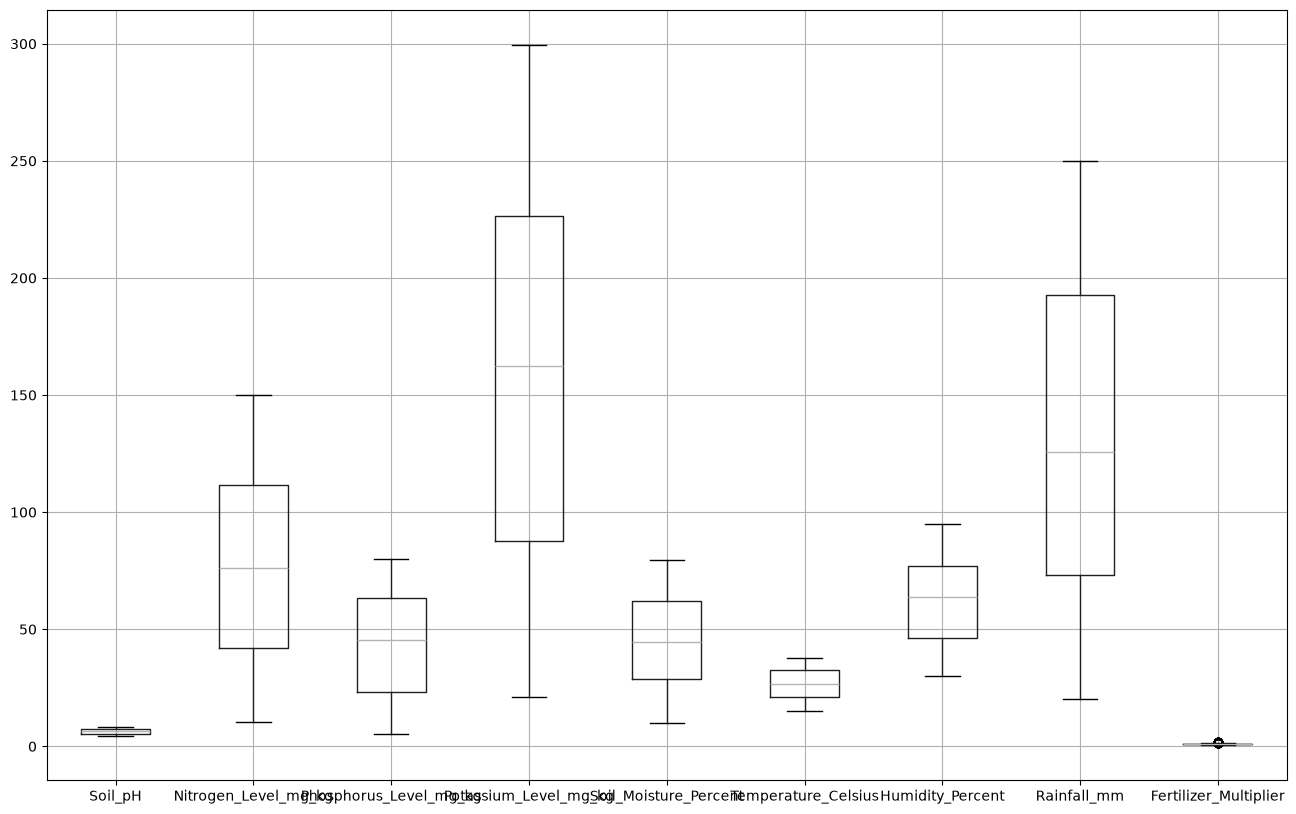

In [38]:
# EDA - Exploratory Data Analysis
plt.figure(figsize=(16,10))
df.boxplot()
plt.show()

In [41]:
# KMeans Algorithm

kmeans = KMeans(n_clusters=3, random_state=1, n_init=20)
labels = kmeans.fit_predict(X_train_scaled)

print("Cluster labels generated successfully!")
print(labels)

Cluster labels generated successfully!
[1 1 0 ... 2 2 1]


In [42]:
inertia = []
for k in range(2,15):
    kmeans = KMeans(n_clusters=k, random_state=1, n_init=20)
    kmeans.fit(X_train_scaled)
    inertia.append(kmeans.inertia_)
    print(kmeans.inertia_)

print("Inertia:\n")
for k, score in zip(range(2,15),inertia):
    print(f"K = {k} Inertia = {score:.2f}")

11085.653225000657
10230.278665683856
9471.420807161223
8852.776431015463
8397.496298795633
8023.492913908569
7694.861597629188
7401.747362482624
7160.5434303063485
6949.521207674359
6730.267760559148
6564.13333375836
6408.214225040292
Inertia:

K = 2 Inertia = 11085.65
K = 3 Inertia = 10230.28
K = 4 Inertia = 9471.42
K = 5 Inertia = 8852.78
K = 6 Inertia = 8397.50
K = 7 Inertia = 8023.49
K = 8 Inertia = 7694.86
K = 9 Inertia = 7401.75
K = 10 Inertia = 7160.54
K = 11 Inertia = 6949.52
K = 12 Inertia = 6730.27
K = 13 Inertia = 6564.13
K = 14 Inertia = 6408.21


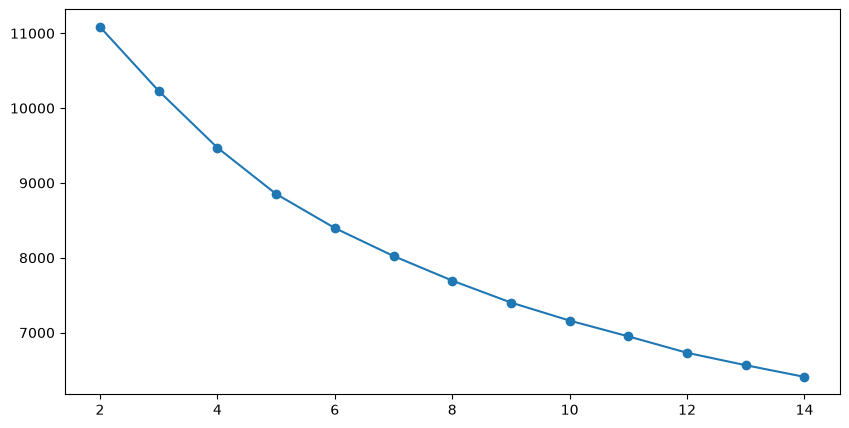

In [43]:
plt.figure(figsize=(10,5))
plt.plot(range(2,15), inertia,marker="o")
plt.show()

In [44]:
silhouette_scores = []
for k in range(2,15):
    kmeans = KMeans(n_clusters=k, random_state=1, n_init=20)
    labels = kmeans.fit_predict(X_train_scaled)
    score = silhouette_score(X_train_scaled,labels)
    silhouette_scores.append(score)

print("Inertia:\n")
for k, score in zip(range(2,15),silhouette_scores):
    print(f"K = {k} Inertia = {score:.2f}")

Inertia:

K = 2 Inertia = 0.16
K = 3 Inertia = 0.12
K = 4 Inertia = 0.13
K = 5 Inertia = 0.14
K = 6 Inertia = 0.14
K = 7 Inertia = 0.14
K = 8 Inertia = 0.14
K = 9 Inertia = 0.14
K = 10 Inertia = 0.14
K = 11 Inertia = 0.15
K = 12 Inertia = 0.15
K = 13 Inertia = 0.15
K = 14 Inertia = 0.15


In [46]:
df_train_clusters = X_train_balanced.copy()
df_train_clusters['Cluster'] = labels
df_train_clusters['Recommended_Crop'] = y_train_balanced

print("Success! Cluster labels appended to the balanced dataset.")
print(df_train_clusters.head())

🎉 Success! Cluster labels appended to the balanced dataset.
   Soil_pH  Nitrogen_Level_mg_kg  Phosphorus_Level_mg_kg  \
0     7.91                  97.4                    51.2   
1     4.90                  83.6                    55.0   
2     5.66                  31.1                     7.5   
3     7.14                  56.7                    70.4   
4     4.56                  29.7                    22.1   

   Potassium_Level_mg_kg  Soil_Moisture_Percent  Temperature_Celsius  \
0                   58.4                   18.0                 29.6   
1                  189.0                   30.2                 27.5   
2                  279.6                   56.5                 31.6   
3                  192.2                   52.6                 29.6   
4                  183.1                   52.3                 17.7   

   Humidity_Percent  Rainfall_mm  Fertilizer_Multiplier  Pest_Risk_Level_Low  \
0              71.0        223.5                   1.19           

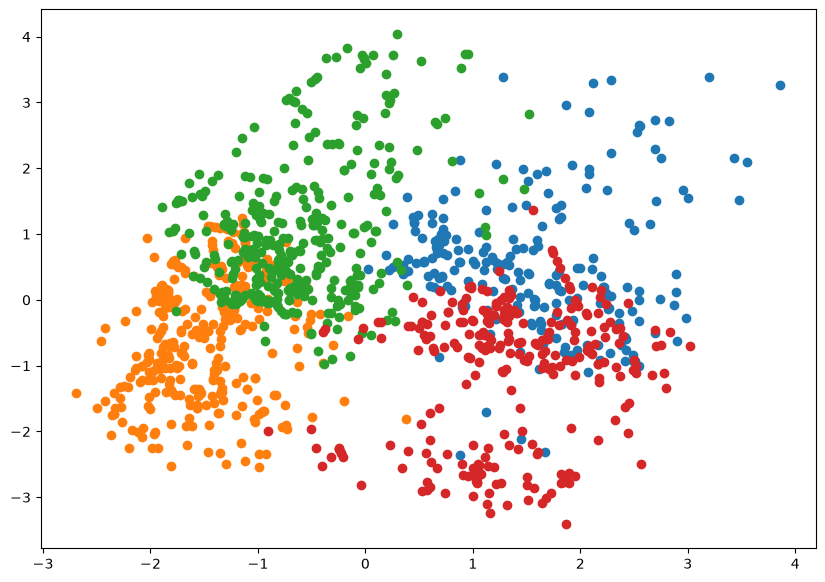

In [47]:
# Plot the clusters
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train_scaled)

#create the dataframe
pca_df = pd.DataFrame({
    "PC1":X_pca[:,0],
    "PC2":X_pca[:,1],
    "Cluster":labels
})

plt.figure(figsize=(10,7))
for cluster in sorted(pca_df["Cluster"].unique()):
    subset = pca_df[pca_df["Cluster"] == cluster]
    plt.scatter(subset['PC1'], subset['PC2'],label=f"Cluster {cluster}")

plt.show()

In [48]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

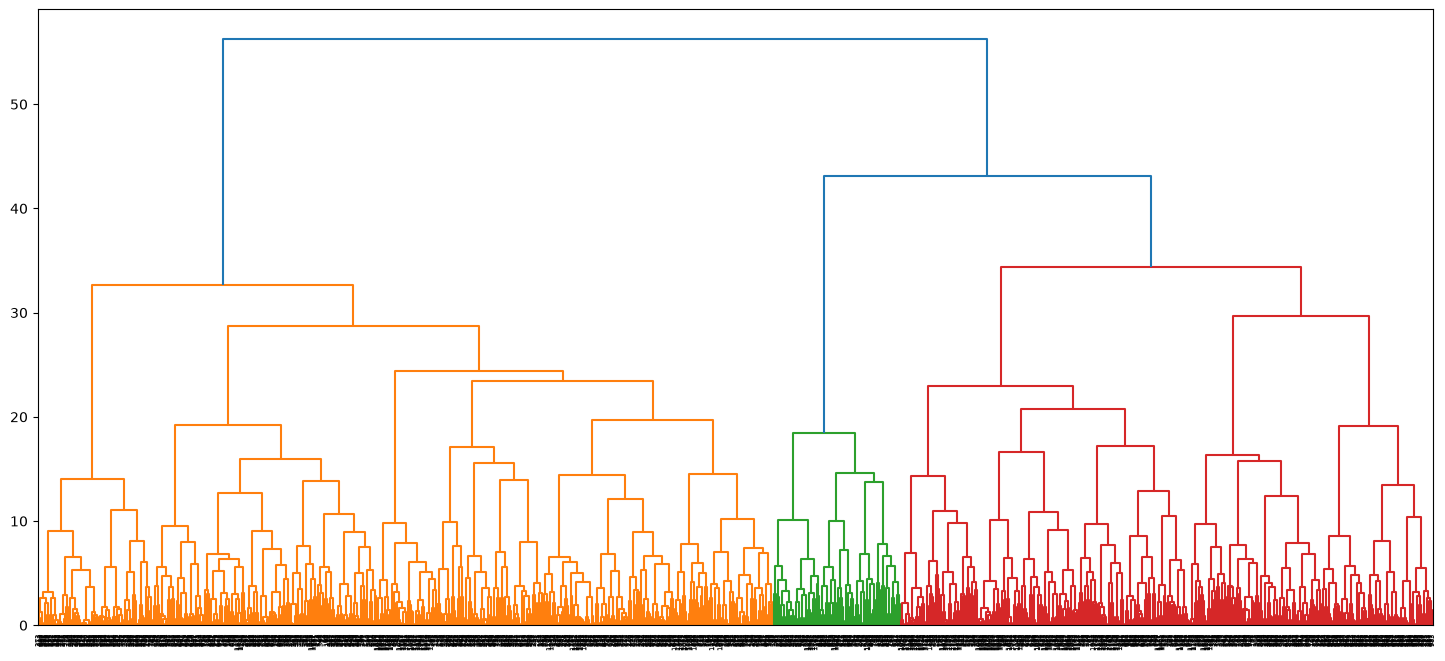

In [49]:
z = linkage(X_train_scaled, method="ward")

#plot dendrogram
plt.figure(figsize=(18,8))
dendrogram(z)
plt.axhline(y=80)
plt.show()